# Level 1 - Task 2: Simple Linear Regression Model
**Codveda ML Internship**

**Goal:** predict a continuous number (house price) from other columns using linear regression.

**Dataset:** Codveda's house price file. It has 506 rows and 13 features and no header row. The target is `MEDV`, the median home value in **$1000s**.

**Steps:** 1) load and preprocess, 2) train, 3) interpret coefficients, 4) evaluate with R-squared and MSE.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

RANDOM_STATE = 42
DATA_PATH = "../data/house_prices.csv"   # change this if your file lives elsewhere

# The file has no header and values are separated by spaces, so we give the names ourselves.
cols = ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE","DIS","RAD","TAX","PTRATIO","B","LSTAT","MEDV"]
df = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=cols)
print("Shape:", df.shape)
df.head()

Shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


**Column guide:** `CRIM` crime rate, `ZN` large-lot zoning, `INDUS` industry share, `CHAS` next to river (0/1), `NOX` air pollution, `RM` average rooms, `AGE` old buildings share, `DIS` distance to job centres, `RAD` highway access, `TAX` property tax, `PTRATIO` pupil-teacher ratio, `B` a demographic index, `LSTAT` % lower-income residents, `MEDV` **price (target)**.

## Step 1: Preprocess

Missing values: 0 | Duplicates: 0
{dtype('float64'): 12, dtype('int64'): 2}


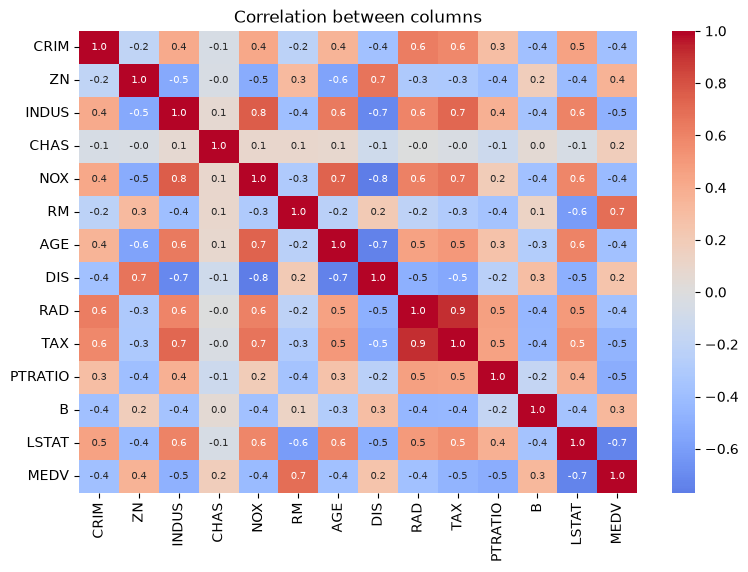

In [2]:
print("Missing values:", int(df.isna().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
print(df.dtypes.value_counts().to_dict())
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlation between columns")
plt.show()

**What this means:** There are no missing values and every column is already numeric, so no cleaning or encoding is needed. The heatmap shows what drives price: `RM` (more rooms) moves with price upward, while `LSTAT` (lower-income share) moves it downward.

In [3]:
X = df.drop(columns=["MEDV"])
y = df["MEDV"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

# Scale using TRAIN data only, then apply to TEST (avoids data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (404, 13) | Test: (102, 13)


## Step 2: Train the model

In [4]:
model = LinearRegression()
model.fit(X_train_s, y_train)
print("Intercept:", round(model.intercept_, 2))

Intercept: 22.8


## Step 3: Interpret the coefficients

feature  coefficient
  LSTAT       -3.612
     RM        3.145
    DIS       -3.082
    RAD        2.251
PTRATIO       -2.038
    NOX       -2.022
    TAX       -1.767
      B        1.130
   CRIM       -1.002
   CHAS        0.719
     ZN        0.696
  INDUS        0.278
    AGE       -0.176


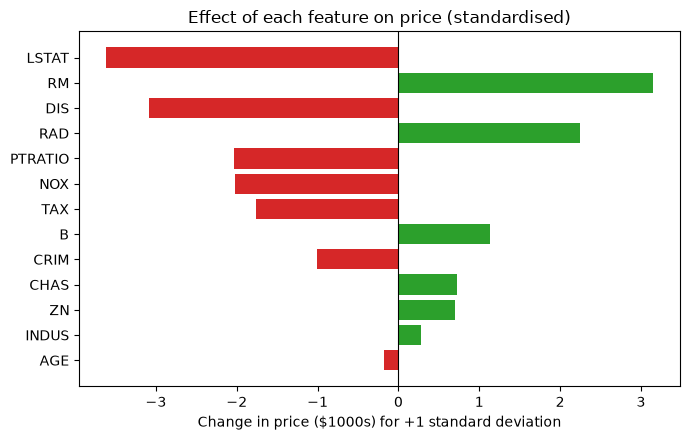

In [5]:
coef = pd.DataFrame({"feature": X.columns, "coefficient": model.coef_})
coef["abs"] = coef["coefficient"].abs()
coef = coef.sort_values("abs", ascending=False).drop(columns="abs").reset_index(drop=True)
coef["coefficient"] = coef["coefficient"].round(3)
print(coef.to_string(index=False))

plt.figure(figsize=(7, 4.5))
colors = ["tab:green" if v > 0 else "tab:red" for v in coef["coefficient"]]
plt.barh(coef["feature"][::-1], coef["coefficient"][::-1], color=colors[::-1])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Effect of each feature on price (standardised)")
plt.xlabel("Change in price ($1000s) for +1 standard deviation")
plt.tight_layout(); plt.show()

**What this means:** Because we standardised the features, each coefficient is the change in price (in $1000s) when that feature goes up by one standard deviation, with the others held fixed. Larger absolute values mean stronger influence, and positive means price goes up.
- **LSTAT** (more lower-income residents) pushes price down the most.
- **RM** (more rooms) pushes price up.
- **DIS, PTRATIO, NOX** (far from jobs, crowded schools, pollution) push price down.
- The **intercept** is the predicted price for an average house.

Note: the `B` column is built from racial demographics. We keep it here only because it is part of Codveda's file. In a real project you should leave it out.

## Step 4: Evaluate the model

In [6]:
pred_train = model.predict(X_train_s)
pred_test  = model.predict(X_test_s)

results = pd.DataFrame({
    "R-squared": [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    "MSE":       [mean_squared_error(y_train, pred_train), mean_squared_error(y_test, pred_test)],
}, index=["Train", "Test"])
results["RMSE ($1000s)"] = np.sqrt(results["MSE"])
print(results.round(3))

       R-squared     MSE  RMSE ($1000s)
Train      0.751  21.641          4.652
Test       0.669  24.291          4.929


**What this means:**
- **R-squared** is the share of price variation the model explains (1.0 is perfect, 0 is no better than guessing the average).
- **MSE** is the average squared error, and **RMSE** is its square root, which is in the same units as price ($1000s), so it reads as a typical miss.
- Train and test scores should be reasonably close. A small drop on the test set is normal; a very large gap would signal overfitting.

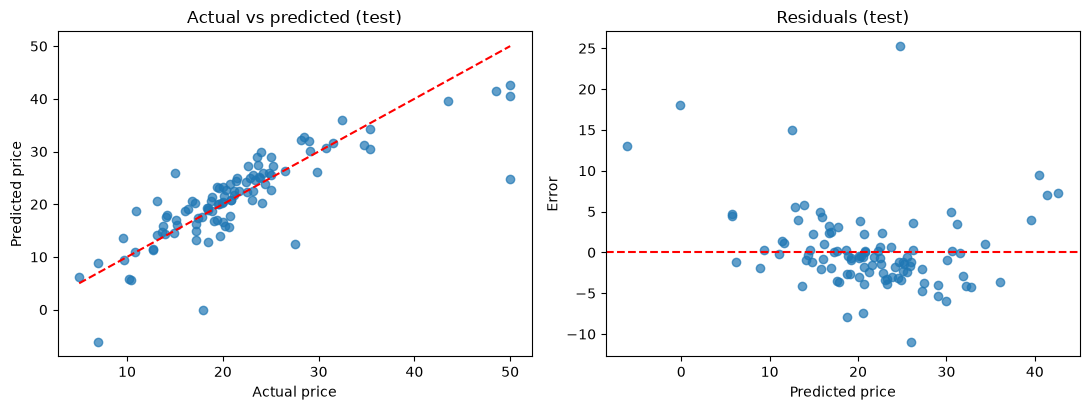

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(y_test, pred_test, alpha=0.7)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price")
ax[0].set_title("Actual vs predicted (test)")
ax[1].scatter(pred_test, y_test - pred_test, alpha=0.7)
ax[1].axhline(0, color="r", linestyle="--"); ax[1].set_xlabel("Predicted price"); ax[1].set_ylabel("Error")
ax[1].set_title("Residuals (test)")
plt.tight_layout(); plt.show()

**What this means:** Points close to the red line in the left chart are good predictions. The right chart should look like a random cloud around zero; a curve or fan shape would mean a straight line is missing some pattern. Check whether the errors grow for the most expensive houses.

## Conclusion
- A linear regression trained on 80% of the data predicts house prices with the R-squared and error shown above.
- The coefficients show which factors raise or lower price (rooms up, lower-income share and pollution down).
- Possible next steps: try Ridge/Lasso, add interaction terms, or use a tree-based model to capture non-linear patterns.